In [1]:
import os, sys, shutil
from tqdm import tqdm
import numpy as np
import pandas as pd
# Set the display options to show all columns
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
from PIL import Image
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import math
import random
from datetime import datetime
from scipy.stats import binomtest
from collections import defaultdict
experiment_version = 1
response_version = 1

stimuli_path = f"stimuli_v{experiment_version}/"
response_path = f"responses_v{experiment_version}/"
dataframe_path = f"dataframes_v{experiment_version}/"

os.makedirs(stimuli_path, exist_ok=True)
os.makedirs(response_path, exist_ok=True)
os.makedirs(dataframe_path, exist_ok=True)

# CREATE EXPERIMENT DATAFRAME AND TRIAL FILES FOR MEADOWS

In [ ]:

#Experiment column key:
df_exp = pd.DataFrame(columns=["experiment", "stim1", "stim2", "stim3", "stim2_strength", "stim3_strength", "target_on_left", "method", "catch_trial", "sample", "subject",  "rep", "mode", "stimtype"])
i=0
stimuli_root = "/export/raid1/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
gt_root = "/export/raid1/home/kneel027/data/umn-imagery/nsddata_stimuli/stimuli/imagery_images/"
method = "braindiffuser_augmentations"
strengths = [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
for sample in tqdm(range(18)):
    gt_sample = f"{sample}_ground_truth"
    gt_sample_path = f"{gt_root}/{sample}.png"
    gt_image = Image.open(gt_sample_path).resize((512,512))
    gt_image.save(f"stimuli_v{experiment_version}/{gt_sample}.png")
    
    if sample < 6:
        stimtype = "simple"
    elif sample < 12:
        stimtype = "complex"
    else:
        stimtype = "concept"
    for mode in ["vision", "imagery"]:
        
        for subj in [1, 2, 5, 7]:
            candidate_pool = []
            gt_pool = []
            for rep in range(10):
                # 1: Experiment 1, experiment to compare identification accuracy of recons with varying strength parameters with correct and incorrect VDVAE structural guidance
                for strength in strengths:
                    candidate_pool.append(f"{sample}_{rep}_subject{subj}_{mode}_{strength:.2f}")
                    recon_path = f"{stimuli_root}{mode}/{method}/{strength}-str_1.0-mix/subject{subj}/{sample}/{rep}.png"
                    # shutil.copy(recon_path, f"stimuli_v{experiment_version}/{sample}_{rep}_subject{subj}_{mode}_{strength:.2f}.png")
                    if mode == "vision" and sample < 12:
                        gt_pool.append(f"{sample}_{rep}_gt_{strength}")
                        gt_recon_path = f"{stimuli_root}{mode}/{method}/{strength:.1f}-str_1.0-mix_gt/subject1/{sample}/{rep}.png"
                        # shutil.copy(gt_recon_path, f"stimuli_v{experiment_version}/{sample}_{rep}_gt_{strength}.png")
            # print(len(candidate_pool))
            # print(len(gt_pool))
            while len(candidate_pool) > 0:
                left_sample = candidate_pool.pop(random.randrange(len(candidate_pool)))
                right_sample = candidate_pool.pop(random.randrange(len(candidate_pool)))
                left_strength = float(left_sample.split("_")[-1])
                right_strength = float(right_sample.split("_")[-1])
                left_rep = int(left_sample.split("_")[1])
                right_rep = int(right_sample.split("_")[1])
                df_exp.loc[i] = {"experiment" : 1, "stim1" : gt_sample, "stim2" : left_sample, "stim3" : right_sample, "stim2_strength" : left_strength, "stim3_strength" : right_strength, "target_on_left" : True, "method" : method, "subject" : subj, "catch_trial" : None, "stim2_rep" : left_rep, "stim3_rep" : right_rep, "mode" : mode, "stimtype" : stimtype, "trial_rep" : 0}
                i+=1
                
            # Ground truth calibration trials, not running for conceptual stimuli.
            if mode == "vision" and sample < 12 and subj == 1:
                while len(gt_pool) > 0:
                    left_sample = gt_pool.pop(random.randrange(len(gt_pool)))
                    right_sample = gt_pool.pop(random.randrange(len(gt_pool)))
                    left_strength = float(left_sample.split("_")[-1])
                    right_strength = float(right_sample.split("_")[-1])
                    
                    df_exp.loc[i] = {"experiment" : 1, "stim1" : gt_sample, "stim2" : left_sample, "stim3" : right_sample, "stim2_strength" : left_strength, "stim3_strength" : right_strength, "target_on_left" : True, "method" : method, "subject" : subj, "catch_trial" : None, "stim2_rep" : left_rep, "stim3_rep" : right_rep, "mode" : "gt", "stimtype" : stimtype, "trial_rep" : 0}
                    i+=1
df_exp = df_exp.sample(frac=1)
print(len(df_exp))


In [ ]:
# Check if all images are present in final stimuli folder
count_not_found = 0
stim_path = f"stimuli_v{experiment_version}/"
for index, row in df_exp.iterrows():
    if not (os.path.exists(f"{stim_path}{row['stim1']}.png")):
        print(f"{row['stim1']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim2']}.png")):
        print(f"{row['stim2']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim3']}.png")):
        print(f"{row['stim3']}.png")
        count_not_found += 1
print(count_not_found)

### Add pID columns to assign trials to different participants

In [ ]:
# Shuffle Experiment 1
df_exp1 = df_exp[df_exp['experiment'] == 1].sample(frac=1, random_state=42)
# Calculate the number of participants needed
exp1_trials_per_participant = 51
num_participants = len(df_exp1) // exp1_trials_per_participant

# Assign pID for Experiment 1
df_exp1['pID'] = [i % num_participants for i in range(len(df_exp1))]

# Combine and shuffle the dataframe to mix up the trials across all experiments
df_exp_pid = df_exp1

# Sort by pID to ensure the dataframe is ordered by participant, facilitating even distribution
df_exp_pid.sort_values(by='pID', inplace=True)

# Ensure pID is the first column
cols = list(df_exp_pid.columns)
cols.insert(0, cols.pop(cols.index('pID')))
df_exp_pid = df_exp_pid[cols]
print(num_participants)

In [ ]:
#Add catch trials within each pID section
df_exp_catch = df_exp_pid.copy()
for pID in np.unique(df_exp_catch['pID']):
    df_pid = df_exp_catch[(df_exp_catch['pID'] == pID)]
    # Ground truth catch trials
    try:
        gt_catch_trials = df_pid.sample(n=9)
    except:
        print(pID, df_pid)
    gt_catch_trials['catch_trial'] = "ground_truth"
    for index, row in gt_catch_trials.iterrows():
        
        order = random.randrange(2)
        ground_truth = row['stim1']
        stims = [ground_truth, row['stim2']]
        
        gt_catch_trials.at[index, 'stim2'] = stims.pop(order)
        gt_catch_trials.at[index, 'stim3'] = stims.pop()
        # Target on left here means the ground truth repeat is on the left
        gt_catch_trials.at[index, 'target_on_left'] = (order == 0)
    df_exp_catch = pd.concat([df_exp_catch, gt_catch_trials])
#shuffle catch trials into the sessions
df_exp_catch = df_exp_catch.sample(frac=1).sort_values(by='pID', kind='mergesort')
print(len(df_exp_catch))
print(len(df_exp_catch[(df_exp_catch['pID'] == 0)]))
print(len(np.unique(df_exp_catch['pID'])))
print(len(df_exp_catch[df_exp_catch['experiment'] == 1]))
# print(len(df_exp_catch[df_exp_catch['experiment'].isin([2, 3])]))

In [ ]:
# Filter the dataframe to get rows where stim2 is equal to stim3
df_stim2_equals_stim3 = df_exp[df_exp['stim2'] == df_exp['stim3']]

# Print the filtered dataframe
print(df_stim2_equals_stim3)

### Save experiment dataframe and tsv files

In [12]:

df_exp_catch.to_csv(f'dataframes_v{experiment_version}/experiment_v{experiment_version}.csv', index=False)
df_catch_exp1 = df_exp_catch[df_exp_catch['experiment'] == 1]
# df_catch_exp2 = df_exp_catch[df_exp_catch['experiment'] == 2]

df_exp_tsv1 = df_catch_exp1[['pID', 'stim1', 'stim2', 'stim3']].copy()
# df_exp_tsv2 = df_catch_exp2[['pID', 'stim1', 'stim2', 'stim3']].copy()
df_exp_tsv1.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1.tsv", sep="\t", index=False, header=False) 
# df_exp_tsv2.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp2.tsv", sep="\t", index=False, header=False) 

# THE FOLLOWING CELLS ARE FOR PROCESSING RESPONSES

In [3]:
experiment_version = 1
response_version = 1
df_experiment = pd.read_csv(dataframe_path + f"experiment_v{experiment_version}.csv")

df_responses = pd.read_csv(f"{response_path}annotations_v{response_version}.csv")

### Parse the responses and associate them with the trials in the experiment dataframe, to have all information available in one dataframe

In [ ]:

# Initialize a list to hold row dictionaries before creating the final dataframe
rows_list = []
df_2afc = df_responses[df_responses["task"] == "2AFC"]
# Parse trials in 2AFC experiment
for index, row in tqdm(df_2afc.iterrows()):
    if row['label'] == row['stim2_id']:
        picked_left = True
    elif row['label'] == row['stim3_id']:
        picked_left = False
    else:
        print("Error")
        break
    start_timestamp = row['time_trial_start']
    end_timestamp = row['time_trial_response']
    start = datetime.fromisoformat(start_timestamp.replace("Z", "+00:00"))
    end = datetime.fromisoformat(end_timestamp.replace("Z", "+00:00"))
    # Calculate the difference in seconds
    response_time = (end - start).total_seconds()
    
    experiment_row = df_experiment[(df_experiment['stim1'] == row['stim1_name']) & (df_experiment['stim2'] == row['stim2_name']) & (df_experiment['stim3'] == row['stim3_name'])]
    if not experiment_row.empty:
        experiment_row = experiment_row.iloc[0]
        if experiment_row['target_on_left']:
            strength = experiment_row['stim2'].split("_")[-1]
        else:
            strength = experiment_row['stim3'].split("_")[-1]
        
        row_data = {
            **experiment_row.to_dict(),
            "strength" : strength,
            "picked_left": picked_left,
            "picked_target": picked_left == experiment_row['target_on_left'],
            "participant": row['participation'],
            "response_time": response_time,
        }
        
        rows_list.append(row_data)
    else:
        print(row['stim1_name'], row['stim2_name'], row['stim3_name'])

# Create the final dataframe from the list of row dictionaries
df_trial_combined = pd.DataFrame(rows_list)

# Dropping the extra index columns added from the experiment_row.to_dict() conversion
df_trial = df_trial_combined.drop(columns=[col for col in df_trial_combined.columns if 'Unnamed' in col])

print(df_trial.head())

### Find trials that didn't get completed in the previous round of the experiment, and save new trial files for another round

In [ ]:
# Initialize a dictionary to count processed trials per pID
processed_trials_count = defaultdict(int)

# Your existing processing loop goes here...
# Update processed_trials_count for each row processed
for index, row_data in df_trial.iterrows():
    processed_trials_count[row_data['pID']] += 1

# Count expected trials per pID from df_experiment
expected_trials_count = df_experiment['pID'].value_counts().to_dict()

# Find pIDs with missing trials by comparing processed and expected counts
missing_trials_pids = {pID: expected_trials_count[pID] - processed_trials_count[pID] 
                       for pID in expected_trials_count 
                       if pID not in processed_trials_count or processed_trials_count[pID] < expected_trials_count[pID]-2}

# Print or handle pIDs with missing trials as needed
print(f"missing {len(missing_trials_pids.values())} pIDs")
for pID, missing_count in missing_trials_pids.items():
    print(f"pID: {pID} has {missing_count} missing trials.")
    
if len(missing_trials_pids.values()) > 0:
    df_exp_missing = df_experiment[df_experiment['pID'].isin(missing_trials_pids.keys())]

    df_catch_exp1_missing = df_exp_missing[df_exp_missing['experiment'] == 1]
    df_catch_exp23_missing = df_exp_missing[df_exp_missing['experiment'].isin([2, 3])]


    df_exp_tsv1_missing = df_catch_exp1_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv23_missing = df_catch_exp23_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv1_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1_missing.tsv", sep="\t", index=False, header=False) 
    df_exp_tsv23_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp23_missing.tsv", sep="\t", index=False, header=False) 

### Parse and remove participants that failed at least 2 catch trials

In [5]:
# number of participants
print("Total participants:", len(df_trial["participant"].unique()))
gt_failures = df_trial[(df_trial['catch_trial'] == 'ground_truth') & (df_trial['picked_target'] == False)].groupby('participant').size()
# print(df_trial[(df_trial['catch_trial'] == 'ground_truth')])
# Identify participants who failed more than 1 ground truth catch trial
participants_to_remove_rule1 = gt_failures[gt_failures > 1].index.tolist()
print("Participants to remove 1:", participants_to_remove_rule1)

# Remove participants who failed the repeat catch trial, and gave different responses for identical trials
# repeat_trials = df_trial[df_trial['rep'] > 0]
# grouped_repeat_trials = repeat_trials.groupby(['stim1', 'stim2', 'stim3'])
# participant_failures = {}
# # Iterate through groups to check consistency in "picked_target" across repetitions
# for _, group in grouped_repeat_trials:
#     if group['picked_target'].nunique() != 1:  # Inconsistent "picked_target" within the group
#         for participant in group['participant'].unique(): 
#             participant_failures[participant] = participant_failures.get(participant, 0) + 1

# # Identify participants who failed at least one set of trial repetitions
# participants_to_remove_rule2 = [participant for participant, failures in participant_failures.items() if failures > 1]
# print("Participants to remove 2:", participants_to_remove_rule2)

participants_to_remove = set(participants_to_remove_rule1)#.union(set(participants_to_remove_rule2))
filtered_df = df_trial[~df_trial['participant'].isin(participants_to_remove)]
print("Clean participants:", len(filtered_df["participant"].unique()))
print(len(df_trial), len(filtered_df))
print(participants_to_remove)
# Filter out catch trials
filtered_df = filtered_df[(filtered_df['catch_trial'].isnull())]
filtered_df.to_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv', index=False)

Total participants: 99
Participants to remove 1: []
Clean participants: 99
4233 4233
set()


# THE FOLLOWING CELLS ARE FOR ANALYZING RESPONSES

In [6]:
experiment_version = 1
response_version = 1
dataframe_path = f"dataframes_v{experiment_version}/"
filtered_df = pd.read_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv')


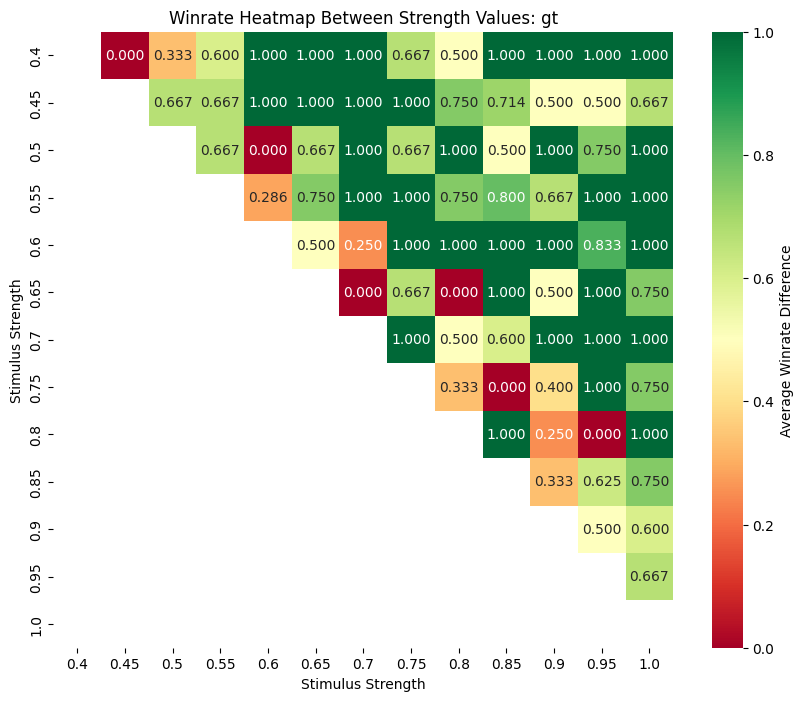

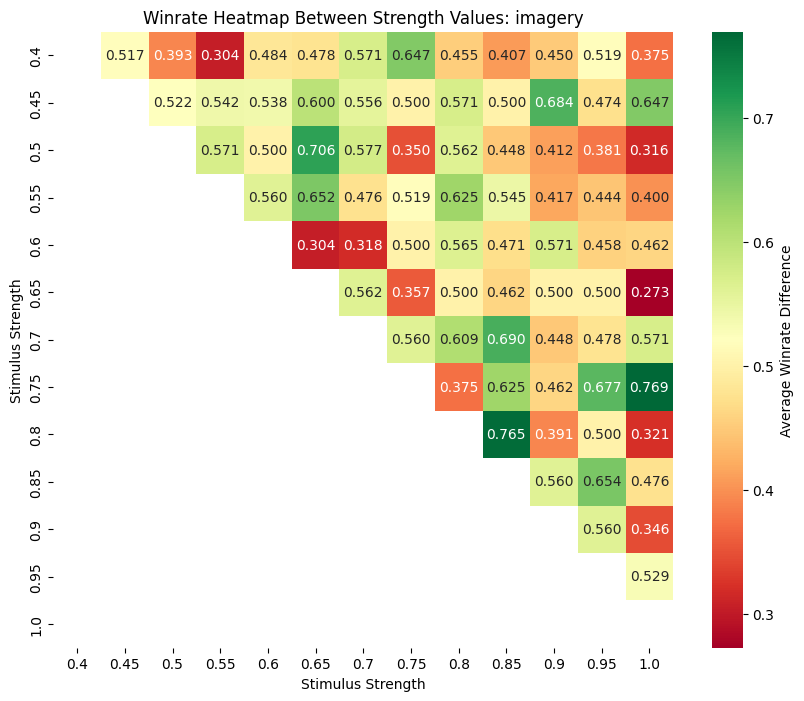

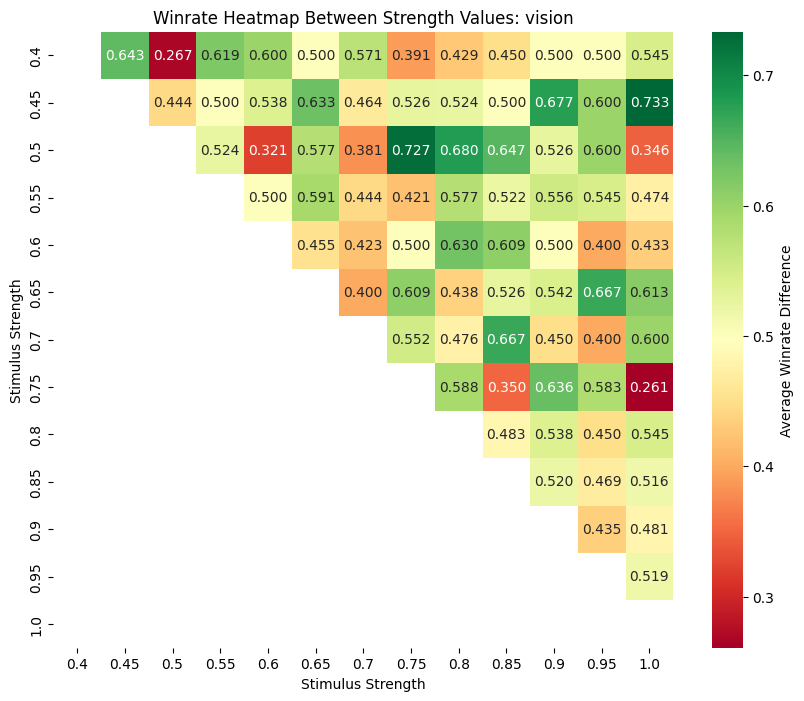

In [11]:
import numpy as np
import seaborn as sns

# Plot average similarity for both "imagery" and "vision" modes
modes = ["gt", "imagery", "vision"]
unique_strength_values = pd.concat([filtered_df['stim2_strength'], filtered_df['stim3_strength']]).unique()
unique_strength_values.sort()

for mode in modes:
    filtered = filtered_df[filtered_df['mode'] == mode]
    
    # Initialize the winrate matrix
    winrate_matrix = pd.DataFrame(index=unique_strength_values, columns=unique_strength_values, dtype=float)

    # Fill the matrix with winrate data
    for strength1 in unique_strength_values:
        for strength2 in unique_strength_values:
            if strength1 != strength2:
                # Filter trials where strength1 and strength2 were compared
                trials = filtered[((filtered['stim2_strength'] == strength1) & (filtered['stim3_strength'] == strength2)) |
                                  ((filtered['stim2_strength'] == strength2) & (filtered['stim3_strength'] == strength1))]

                if not trials.empty:
                    # Calculate winrate where stim2 was picked when strength1 was in stim2 position
                    winrate = trials.apply(
                        lambda row: row['picked_left'] if row['stim2_strength'] == strength1 else not row['picked_left'], axis=1
                    ).mean()

                    # Assign winrate
                    winrate_matrix.at[strength1, strength2] = winrate

    # Create a mask for the lower triangle
    mask = np.tril(np.ones_like(winrate_matrix, dtype=bool))

    # Plot the heatmap with the mask applied
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        winrate_matrix.astype(float),
        cmap='RdYlGn',
        mask=mask,
        annot=True,
        fmt=".3f",
        cbar_kws={'label': 'Average Winrate Difference'}
    )
    plt.title(f'Winrate Heatmap Between Strength Values: {mode}')
    plt.xlabel('Stimulus Strength')
    plt.ylabel('Stimulus Strength')
    plt.show()

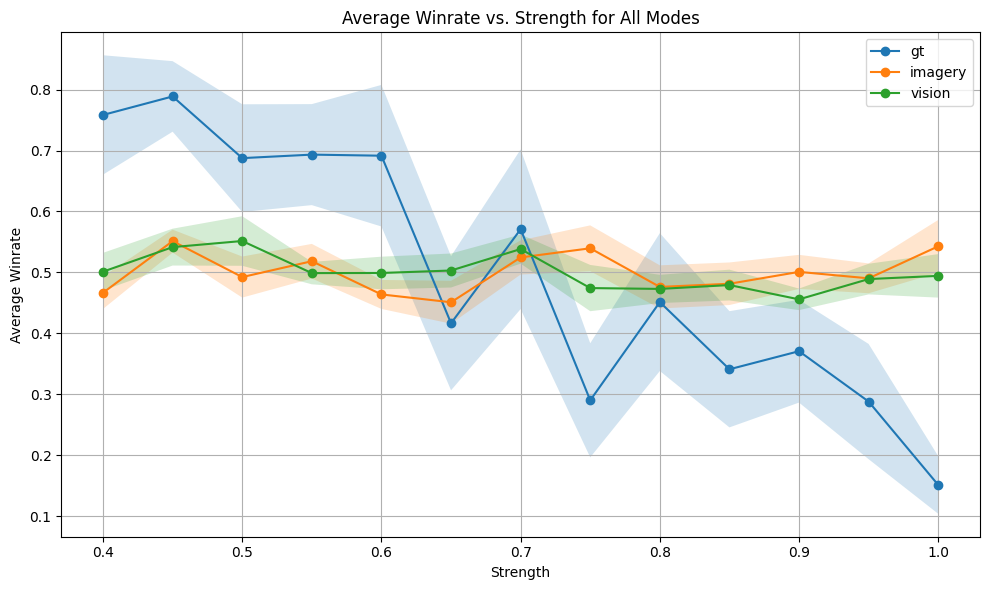

In [15]:
import numpy as np
import seaborn as sns

# Plot average similarity for both "imagery" and "vision" modes
modes = ["gt", "imagery", "vision"]
unique_strength_values = pd.concat([filtered_df['stim2_strength'], filtered_df['stim3_strength']]).unique()
unique_strength_values.sort()

plt.figure(figsize=(10, 6))

for mode in modes:
    filtered = filtered_df[filtered_df['mode'] == mode]

    # Initialize the winrate matrix
    winrate_matrix = pd.DataFrame(index=unique_strength_values, columns=unique_strength_values, dtype=float)

    # Fill the matrix with winrate data
    for strength1 in unique_strength_values:
        for strength2 in unique_strength_values:
            if strength1 != strength2:
                # Filter trials where strength1 and strength2 were compared
                trials = filtered[((filtered['stim2_strength'] == strength1) & (filtered['stim3_strength'] == strength2)) |
                                  ((filtered['stim2_strength'] == strength2) & (filtered['stim3_strength'] == strength1))]

                if not trials.empty:
                    # Calculate winrate where stim2 was picked when strength1 was in stim2 position
                    winrate = trials.apply(
                        lambda row: row['picked_left'] if row['stim2_strength'] == strength1 else not row['picked_left'], axis=1
                    ).mean()

                    # Assign winrate
                    winrate_matrix.at[strength1, strength2] = winrate
                    winrate_matrix.at[strength2, strength1] = 1 - winrate

    # Fill the upper triangle with the inverted lower triangle to increase statistical power
    for i in range(len(unique_strength_values)):
        for j in range(i):
            winrate_matrix.iloc[j, i] = 1 - winrate_matrix.iloc[i, j]

    # Calculate the average winrate for each unique strength value
    average_winrate = winrate_matrix.mean(axis=1)

    # Calculate standard error for each strength
    winrate_std = winrate_matrix.std(axis=1)
    n_trials = winrate_matrix.count(axis=1)
    winrate_se = winrate_std / np.sqrt(n_trials)

    # Convert to a DataFrame for plotting
    average_winrate_df = average_winrate.reset_index()
    average_winrate_df.columns = ['Strength', 'Winrate']
    average_winrate_df['Winrate_SE'] = winrate_se.values
    average_winrate_df.sort_values('Strength', inplace=True)

    # Plot the line with label
    plt.plot(average_winrate_df['Strength'], average_winrate_df['Winrate'], marker='o', linestyle='-', label=mode)

    # Add error bars using fill_between
    plt.fill_between(
        average_winrate_df['Strength'],
        average_winrate_df['Winrate'] - average_winrate_df['Winrate_SE'],
        average_winrate_df['Winrate'] + average_winrate_df['Winrate_SE'],
        alpha=0.2
    )

plt.xlabel('Strength')
plt.ylabel('Average Winrate')
plt.title('Average Winrate vs. Strength for All Modes')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


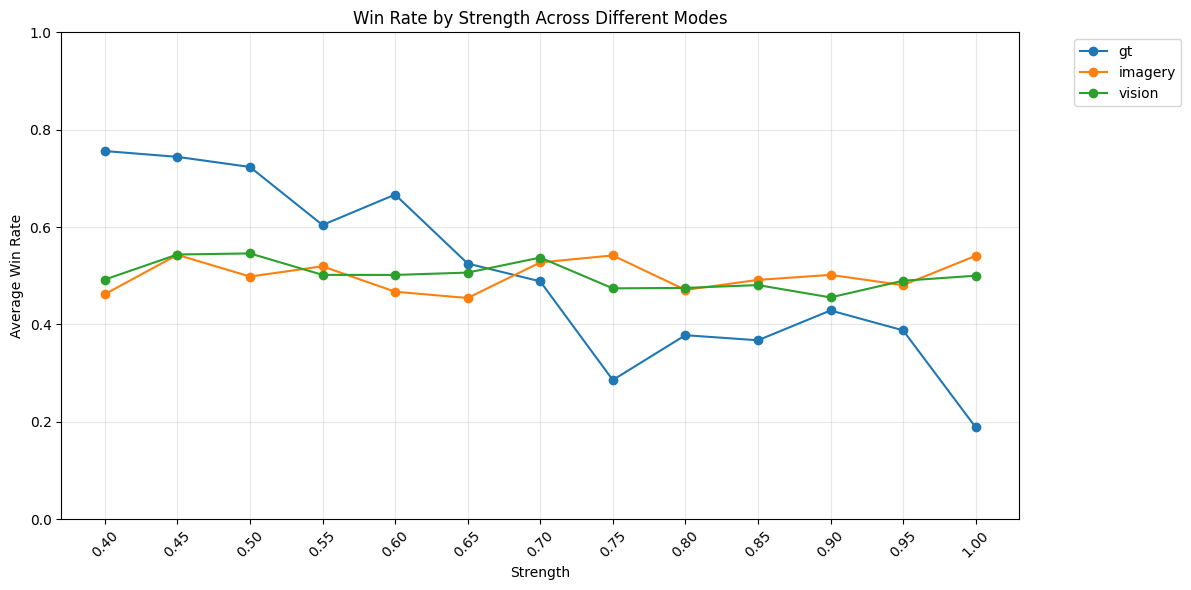

In [17]:
# Convert strength columns to float
df = filtered_df.copy()
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert strength columns to float
df['stim2_strength'] = df['stim2_strength'].astype(float)
df['stim3_strength'] = df['stim3_strength'].astype(float)

# Create a melted dataframe for pairwise comparisons
melted = pd.DataFrame({
    'strength': pd.concat([df['stim2_strength'], df['stim3_strength']]),
    'win': pd.concat([df['picked_left'], ~df['picked_left']]),
    'mode': pd.concat([df['mode'], df['mode']])
})

# Get unique sorted strengths and modes
strengths = sorted(melted['strength'].unique())
modes = melted['mode'].unique()

# Calculate average win rate by strength and mode
win_rates = []
for mode in modes:
    mode_df = melted[melted['mode'] == mode]
    mode_rates = []
    for strength in strengths:
        # Get all comparisons involving this strength
        strength_win = mode_df[mode_df['strength'] == strength]['win']
        if not strength_win.empty:
            mode_rates.append(strength_win.mean())
        else:
            mode_rates.append(np.nan)
    win_rates.append(mode_rates)

# Create plot
plt.figure(figsize=(12, 6))
for mode, rates in zip(modes, win_rates):
    plt.plot(strengths, rates, marker='o', linestyle='-', label=mode)

# Formatting
plt.title('Win Rate by Strength Across Different Modes')
plt.xlabel('Strength')
plt.ylabel('Average Win Rate')
plt.xticks(strengths, rotation=45)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()